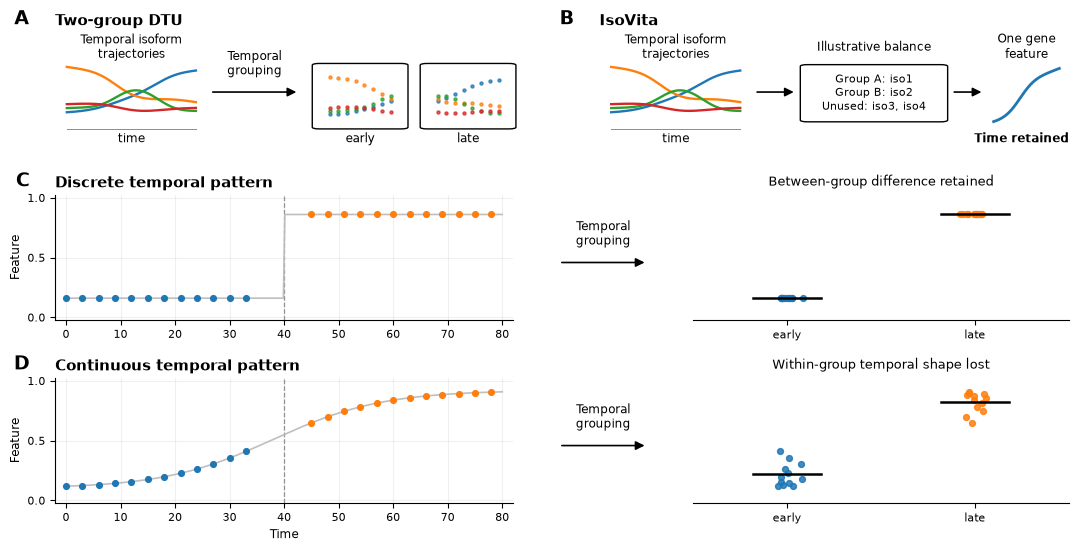

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


BLUE, ORANGE = "tab:blue", "tab:orange"
ISOFORM_COLORS = [BLUE, ORANGE, "tab:green", "tab:red"]


def clean_axis(ax, show_y=True):
    ax.spines[["top", "right"]].set_visible(False)
    if not show_y:
        ax.spines["left"].set_visible(False)
        ax.set_yticks([])
    ax.tick_params(labelsize=8)


def panel_title(ax, letter, title):
    ax.text(
        -0.055, 1.035, letter,
        transform=ax.transAxes,
        fontsize=14, fontweight="bold",
        ha="right", va="bottom", clip_on=False,
    )
    ax.text(
        0, 1.035, title,
        transform=ax.transAxes,
        fontsize=11, fontweight="bold", va="bottom",
    )


def arrow_axes(ax, start, end, text=None, text_offset=0.14):
    ax.add_patch(
        FancyArrowPatch(
            start, end,
            transform=ax.transAxes,
            arrowstyle="-|>",
            mutation_scale=13,
            linewidth=1.2,
            color="black",
            clip_on=False,
        )
    )
    if text:
        ax.text(
            (start[0] + end[0]) / 2,
            (start[1] + end[1]) / 2 + text_offset,
            text,
            transform=ax.transAxes,
            ha="center", va="center", fontsize=8.5,
        )


def rounded_box(ax, xy, width, height, text):
    ax.add_patch(
        FancyBboxPatch(
            xy, width, height,
            transform=ax.transAxes,
            boxstyle="round,pad=0.012,rounding_size=0.015",
            facecolor="white",
            edgecolor="black",
            linewidth=1,
        )
    )
    ax.text(
        xy[0] + width / 2,
        xy[1] + height / 2,
        text,
        transform=ax.transAxes,
        ha="center", va="center", fontsize=8,
    )


# ============================================================
# Shared input trajectories for panels A and B
# ============================================================

def shared_isoform_trajectories():
    """One shared input for A/B, with fractions summing to one."""
    time = np.linspace(0, 1, 160)
    abundance = np.vstack([
        0.14 + 0.70 / (1 + np.exp(-(time - 0.50) * 9)),
        0.72 - 0.38 * time,
        0.20 + 0.43 * np.exp(-((time - 0.56) / 0.20) ** 2),
        np.full_like(time, 0.25),
    ])
    fractions = abundance / abundance.sum(axis=0, keepdims=True)
    return time, fractions


def draw_shared_trajectories(ax, time, fractions):
    """Identical curves, colors, scaling, and placement in A and B."""
    x0, x1, y0, height = 0.025, 0.30, 0.23, 0.53

    for curve, color in zip(fractions, ISOFORM_COLORS):
        ax.plot(
            x0 + (x1 - x0) * time,
            y0 + height * curve / 0.6,
            color=color, lw=1.7,
            transform=ax.transAxes,
        )

    ax.text(
        (x0 + x1) / 2, 0.88,
        "Temporal isoform\ntrajectories",
        transform=ax.transAxes,
        ha="center", va="center", fontsize=8.5,
    )
    ax.plot(
        [x0, x1], [0.19, 0.19],
        color="0.55", lw=0.7,
        transform=ax.transAxes,
    )
    ax.text(
        (x0 + x1) / 2, 0.075, "time",
        transform=ax.transAxes,
        ha="center", fontsize=8.5,
    )


# ============================================================
# Panel A: conventional grouping
# ============================================================

def panel_A_conventional(ax, time, fractions):
    ax.set_axis_off()
    panel_title(ax, "A", "Two-group DTU")
    draw_shared_trajectories(ax, time, fractions)

    arrow_axes(
        ax, (0.33, 0.50), (0.52, 0.50),
        "Temporal\ngrouping",
        text_offset=0.24,
    )

    # Preserve the same samples, but replace time with group labels.
    # Each sample profile contains all four isoform fractions.
    for center, mask, label in [
        (0.65, time < 0.5, "early"),
        (0.88, time >= 0.5, "late"),
    ]:
        rounded_box(
            ax, (center - 0.09, 0.20),
            0.18, 0.53, "",
        )

        values = fractions[:, mask]
        indices = np.linspace(
            0, values.shape[1] - 1, 8
        ).astype(int)
        offsets = np.linspace(-0.065, 0.065, len(indices))

        for offset, index in zip(offsets, indices):
            for j, color in enumerate(ISOFORM_COLORS):
                ax.plot(
                    center + offset,
                    0.23 + 0.44 * values[j, index] / 0.6,
                    "o", ms=2.2,
                    color=color, alpha=0.75,
                    transform=ax.transAxes,
                )

        ax.text(
            center, 0.075, label,
            transform=ax.transAxes,
            ha="center", fontsize=8.5,
        )


# ============================================================
# Panel B: feature condensation
# ============================================================

def panel_B_isovita(ax, time, fractions):
    ax.set_axis_off()
    panel_title(ax, "B", "IsoVita")
    draw_shared_trajectories(ax, time, fractions)

    arrow_axes(ax, (0.33, 0.50), (0.42, 0.50))

    rounded_box(
        ax, (0.44, 0.26), 0.29, 0.46,
        "Group A: iso1\n"
        "Group B: iso2\n"
        "Unused: iso3, iso4",
    )
    ax.text(
        0.585, 0.88, "Illustrative balance",
        transform=ax.transAxes,
        ha="center", va="center", fontsize=8.5,
    )

    arrow_axes(ax, (0.75, 0.50), (0.82, 0.50))

    # Compute the feature from the displayed input trajectories.
    # Membership is schematic, not a fitted IsoVita result.
    feature = np.log(fractions[0] / fractions[1])
    scaled = (feature - feature.min()) / np.ptp(feature)

    ax.plot(
        0.84 + 0.14 * time,
        0.25 + 0.45 * scaled,
        color=BLUE, lw=2,
        transform=ax.transAxes,
    )
    ax.text(
        0.91, 0.88, "One gene\nfeature",
        transform=ax.transAxes,
        ha="center", va="center", fontsize=8.5,
    )
    ax.text(
        0.90, 0.075, "Time retained",
        transform=ax.transAxes,
        ha="center", fontsize=8.5, fontweight="bold",
    )


# ============================================================
# Panels C and D: conceptual temporal patterns
# ============================================================

def conceptual_trajectory(kind, time):
    if kind == "discrete":
        return np.where(time < 40, 0.16, 0.86)

    if kind == "continuous":
        return 0.10 + 0.82 / (
            1 + np.exp(-(time - 38) / 10)
        )

    raise ValueError(kind)


def sample_points(kind):
    # Original sampling and lower-panel trajectories are unchanged.
    time = np.concatenate([
        np.arange(0, 36, 3),
        np.arange(45, 81, 3),
    ])
    return time, conceptual_trajectory(kind, time)


def row_left(ax, letter, name, kind, bottom=False):
    panel_title(ax, letter, name)

    time, y = sample_points(kind)
    fine_time = np.linspace(0, 80, 300)

    ax.plot(
        fine_time,
        conceptual_trajectory(kind, fine_time),
        color="0.75", lw=1.2, zorder=1,
    )

    for mask, color in [
        (time < 40, BLUE),
        (time > 40, ORANGE),
    ]:
        ax.scatter(
            time[mask], y[mask],
            s=17, color=color, zorder=2,
        )

    ax.axvline(
        40, linestyle="--",
        lw=0.9, color="0.55", zorder=0,
    )
    ax.set(
        xlim=(-2, 82),
        ylim=(-0.02, 1.02),
        yticks=[0, 0.5, 1],
    )
    ax.set_ylabel("Feature", fontsize=8.5)

    if bottom:
        ax.set_xlabel("Time", fontsize=8.5)

    ax.grid(alpha=0.18)
    clean_axis(ax)


def row_middle(ax):
    ax.set_axis_off()
    arrow_axes(
        ax, (0.08, 0.46), (0.92, 0.46),
        "Temporal\ngrouping",
        text_offset=0.23,
    )


def row_right(ax, kind, outcome):
    time, y = sample_points(kind)

    for xpos, mask, color, seed in [
        (
            1, time < 40, BLUE,
            111 if kind == "discrete" else 112,
        ),
        (
            2, time > 40, ORANGE,
            211 if kind == "discrete" else 212,
        ),
    ]:
        values = y[mask]
        rng = np.random.default_rng(seed)

        ax.scatter(
            xpos + rng.normal(0, 0.035, len(values)),
            values,
            s=18, alpha=0.85,
            color=color, zorder=2,
        )
        ax.plot(
            [xpos - 0.18, xpos + 0.18],
            [values.mean()] * 2,
            color="black", lw=1.8, zorder=3,
        )

    ax.set(
        xlim=(0.5, 2.5),
        ylim=(-0.02, 1.02),
    )
    ax.set_xticks([1, 2], ["early", "late"])
    clean_axis(ax, show_y=False)

    # Above-plot labels avoid extra whitespace below each row.
    ax.set_title(outcome, fontsize=9, pad=7)


# ============================================================
# Assemble compact figure
# ============================================================

def make_figure(path=None):
    fig = plt.figure(figsize=(11.2, 5.8))

    outer = fig.add_gridspec(
        3, 1,
        height_ratios=[0.95, 1, 1],
        hspace=0.48,
        left=0.075,
        right=0.98,
        top=0.93,
        bottom=0.095,
    )

    top = outer[0].subgridspec(
        1, 2, wspace=0.16
    )

    time, fractions = shared_isoform_trajectories()

    panel_A_conventional(
        fig.add_subplot(top[0, 0]),
        time, fractions,
    )
    panel_B_isovita(
        fig.add_subplot(top[0, 1]),
        time, fractions,
    )

    rows = [
        (
            "C", "Discrete temporal pattern", "discrete",
            "Between-group difference retained",
        ),
        (
            "D", "Continuous temporal pattern", "continuous",
            "Within-group temporal shape lost",
        ),
    ]

    for i, (letter, name, kind, outcome) in enumerate(
        rows, start=1
    ):
        row = outer[i].subgridspec(
            1, 3,
            width_ratios=[1.22, 0.28, 1],
            wspace=0.12,
        )

        row_left(
            fig.add_subplot(row[0, 0]),
            letter, name, kind,
            bottom=(letter == "D"),
        )
        row_middle(fig.add_subplot(row[0, 1]))
        row_right(
            fig.add_subplot(row[0, 2]),
            kind, outcome,
        )

    # Move the top row downward without changing C–D spacing.
    for ax in fig.axes[:2]:
        pos = ax.get_position()
        ax.set_position([
            pos.x0,
            pos.y0 - 0.025,
            pos.width,
            pos.height,
        ])

    if path is not None:
        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.04,
        )

    return fig


if __name__ == "__main__":
    fig = make_figure()
    plt.show()